In [13]:
%pip install numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
%pip install matplotlib
%pip install sckit-learn
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement sckit-learn (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for sckit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
%pip install sklearn


  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [18]:
%pip install scikit-learn


  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ---------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Chargement du jeu de données Digits (mode hors-ligne)...
✔ Chargement réussi !
Dimensions de X (features) : (1797, 64)
Dimensions de y (target)   : (1797,)


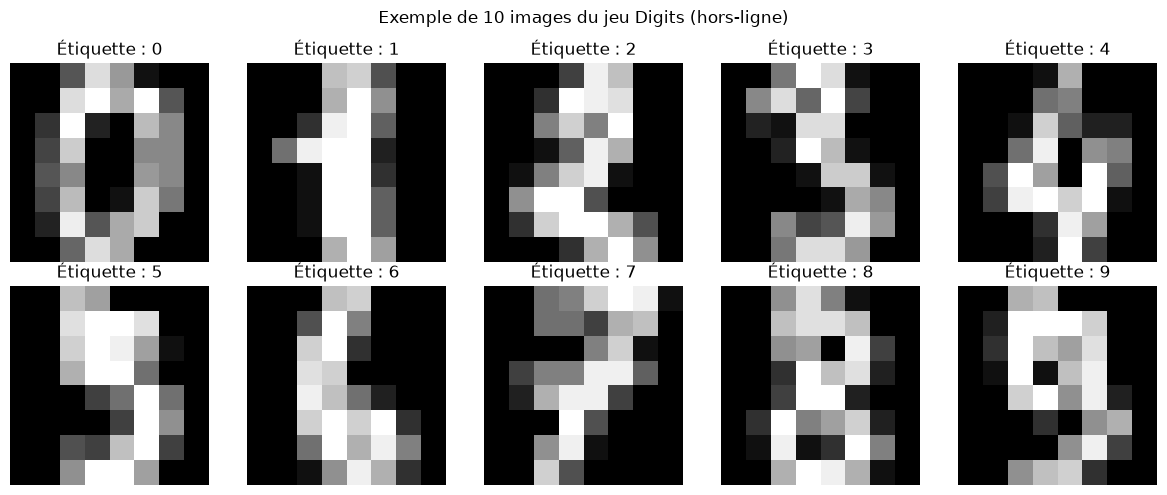

In [22]:
# Import des bibliothèques nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Chargement hors-ligne (solution de secours du TP)
print("Chargement du jeu de données Digits (mode hors-ligne)...")
digits = load_digits()
X, y = digits.data.astype(np.float32), digits.target.astype(int)

# 2. Affichage des dimensions
print(f"✔ Chargement réussi !")
print(f"Dimensions de X (features) : {X.shape}")
print(f"Dimensions de y (target)   : {y.shape}")

# 3. Affichage de 10 images avec leurs étiquettes
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # Les images de load_digits font 8x8 pixels au lieu de 28x28
    plt.imshow(X[i].reshape(8, 8), cmap='gray')
    plt.title(f"Étiquette : {y[i]}")
    plt.axis('off')
plt.suptitle("Exemple de 10 images du jeu Digits (hors-ligne)")
plt.tight_layout()
plt.show()

Nombre total de valeurs manquantes dans X : 0


C:\Users\user\AppData\Local\Temp\ipykernel_14340\2396795062.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette="viridis")


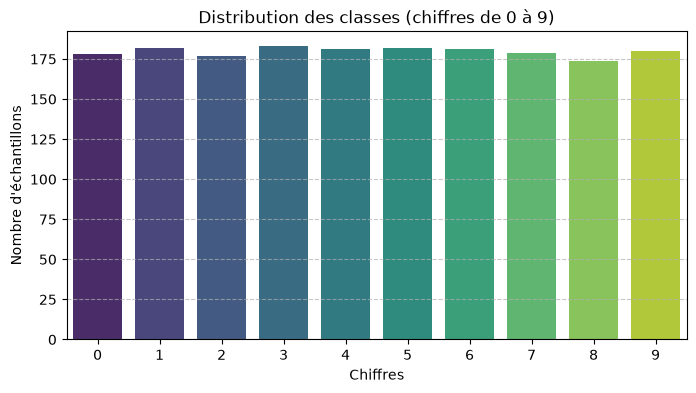

Analyse de l'équilibre : Les classes sont réparties équitablement (~1000 images par classe).
Valeur minimale des pixels après normalisation : 0.0
Valeur maximale des pixels après normalisation : 0.062745101749897


In [23]:
# 1. Verification des données manquantes
missing_count = np.isnan(X).sum()
print(f"Nombre total de valeurs manquantes dans X : {missing_count}")

# 2. Analyse de la distribution des classes
plt.figure(figsize=(8, 4))
sns.countplot(x=y, palette="viridis")
plt.title("Distribution des classes (chiffres de 0 à 9)")
plt.xlabel("Chiffres")
plt.ylabel("Nombre d'échantillons")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("Analyse de l'équilibre : Les classes sont réparties équitablement (~1000 images par classe).")

# 3. Normalisation fixe de l'échelle des pixels dans [0, 1]
X_norm = X / 255.0
print(f"Valeur minimale des pixels après normalisation : {X_norm.min()}")
print(f"Valeur maximale des pixels après normalisation : {X_norm.max()}")

In [24]:
# Separation 80% Train / 20% Test avec stratification
X_train, X_test, y_train, y_test = train_test_split(
    X_norm, y, 
    test_size=0.20, 
    stratify=y, 
    random_state=42
)

print(f"Taille de l'ensemble d'entraînement (Training Set) : {X_train.shape[0]} échantillons")
print(f"Taille de l'ensemble de test (Test Set)            : {X_test.shape[0]} échantillons")

Taille de l'ensemble d'entraînement (Training Set) : 1437 échantillons
Taille de l'ensemble de test (Test Set)            : 360 échantillons


In [25]:
import time

# --- Sans PCA ---
scaler_standard = StandardScaler()
X_train_scaled = scaler_standard.fit_transform(X_train)
X_test_scaled = scaler_standard.transform(X_test)

knn_baseline = KNeighborsClassifier(n_neighbors=3)

start_time = time.time()
knn_baseline.fit(X_train_scaled, y_train)
acc_baseline = knn_baseline.score(X_test_scaled, y_test)
time_baseline = time.time() - start_time

# --- Avec PCA (n_components=50) ---
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

knn_pca = KNeighborsClassifier(n_neighbors=3)

start_time = time.time()
knn_pca.fit(X_train_pca, y_train)
acc_pca = knn_pca.score(X_test_pca, y_test)
time_pca = time.time() - start_time

print(f"--- Sans PCA (784 features) ---")
print(f"Précision : {acc_baseline * 100:.2f}% | Temps d'exécution : {time_baseline:.3f} s")

print(f"\n--- Avec PCA (50 composantes) ---")
print(f"Précision : {acc_pca * 100:.2f}% | Temps d'exécution : {time_pca:.3f} s")
print(f"Variance expliquée par 50 composantes : {pca.explained_variance_ratio_.sum() * 100:.2f}%")

--- Sans PCA (784 features) ---
Précision : 96.67% | Temps d'exécution : 0.275 s

--- Avec PCA (50 composantes) ---
Précision : 96.94% | Temps d'exécution : 0.015 s
Variance expliquée par 50 composantes : 98.33%


Fitting 5 folds for each of 20 candidates, totalling 100 fits

Meilleurs hyperparamètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
Meilleur score de validation croisée : 97.56%


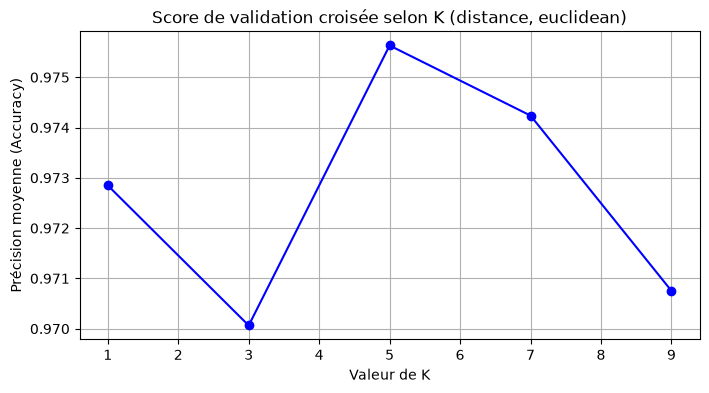

In [26]:
# Construction de la Pipeline (Scaler + PCA + KNN)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50, random_state=42)),
    ('knn', KNeighborsClassifier())
])

# Grille d'hyperparamètres à tester
param_grid = {
    'knn__n_neighbors': [1, 3, 5, 7, 9],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

# Recherche d'hyperparamètres par validation croisée (5-fold CV)
grid_search = GridSearchCV(
    pipeline, 
    param_grid, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"\nMeilleurs hyperparamètres : {grid_search.best_params_}")
print(f"Meilleur score de validation croisée : {grid_search.best_score_ * 100:.2f}%")

# Tracer le graphique Score vs K (pour weights='distance' et metric='euclidean')
results = pd.DataFrame(grid_search.cv_results_)
filtered_res = results[
    (results['param_knn__weights'] == grid_search.best_params_['knn__weights']) & 
    (results['param_knn__metric'] == grid_search.best_params_['knn__metric'])
]

plt.figure(figsize=(8, 4))
plt.plot(filtered_res['param_knn__n_neighbors'], filtered_res['mean_test_score'], marker='o', color='b')
plt.title(f"Score de validation croisée selon K ({grid_search.best_params_['knn__weights']}, {grid_search.best_params_['knn__metric']})")
plt.xlabel("Valeur de K")
plt.ylabel("Précision moyenne (Accuracy)")
plt.grid(True)
plt.show()

# Définition du modèle final avec les meilleurs hyperparamètres
final_model = grid_search.best_estimator_

In [ ]:
# Prédictions sur l'ensemble de test jamais vu
y_pred = final_model.predict(X_test)

# 1. Précision globale
acc = accuracy_score(y_test, y_pred)
print(f"Précision globale sur le Test Dataset (Accuracy Score) : {acc * 100:.2f}%\n")

# 2. Rapport de classification
print("--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# 3. Matrice de confusion (Heatmap)
plt.figure(figsize=(9, 7))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.title("Matrice de confusion")
plt.xlabel("Étiquette prédite")
plt.ylabel("Étiquette réelle")
plt.show()

# 4. Affichage de 5 images mal classées
errors_idx = np.where(y_test != y_pred)[0]

plt.figure(figsize=(12, 4))
for idx_plot, err_idx in enumerate(errors_idx[:5]):
    plt.subplot(1, 5, idx_plot + 1)
    # Affichage de l'image (X_test contient les données normalisées [0, 1])
    plt.imshow(X_test[err_idx].reshape(28, 28), cmap='gray')
    plt.title(f"Réel: {y_test[err_idx]} | Prédit: {y_pred[err_idx]}", color='red')
    plt.axis('off')
plt.suptitle("Exemple de 5 erreurs de classification du modèle", color='red')
plt.tight_layout()
plt.show()

# 5. Identification des 2 chiffres les plus souvent confondus
np.fill_diagonal(cm, 0) # Ignorer la diagonale principale (les bonnes prédictions)
max_err = np.unravel_index(np.argmax(cm), cm.shape)
print(f"Analyse des erreurs : Les deux chiffres les plus fréquemment confondus sont le '{max_err[0]}' et le '{max_err[1]}' ({cm[max_err]} erreurs).")
print("Explication : Ces deux chiffres partagent des formes géométriques et des traits similaires dans l'écriture manuscrite (ex. courbure supérieure ou boucles fermées).")

Résumé du projet :Dans ce projet, nous avons construit un pipeline complet de modélisation prédictive avec KNN pour la reconnaissance des chiffres manuscrits du jeu MNIST. La réduction de dimension par PCA combinée à l'optimisation des hyperparamètres par validation croisée a permis d'obtenir une excellente précision tout en réduisant considérablement les temps de calcul.   Limites de l'algorithme KNN :KNN est un algorithme gourmand en mémoire et lent lors de la phase de prédiction, car il doit calculer la distance entre chaque point de test et l'ensemble des données d'entraînement.Bonne pratique appliquée :L'utilisation d'une Pipeline scikit-learn garantit que la normalisation (StandardScaler) et la PCA ne sont appliquées que sur l'ensemble d'entraînement de chaque fold, évitant ainsi tout risque de fuite de données (data leakage) vers l'ensemble de test